Build a Text2SQL ReAct Agentic AI System with LangChain

In this project, we will use create_react_agent function from LangGraph, which offers a more robust implementation compared to the deprecated LangChain version. The workflow consists of the following components:

Agent System Prompt: The agent is designed to interpret user questions and generate syntactically correct SQL queries.

SQL Database Tools: The system uses tools to interact with the database schema and validate queries:

DB_QUERY: Executes the generated SQL query.
DB_SCHEMA: Fetches the schema details of the database.
DB_LIST_TABLES: Lists all tables in the database.
DB_QUERY_CHECKER: Validates the correctness of the SQL query before execution.
SQL Database Engine: Executes the validated SQL queries and retrieves the required data from the database.

ReAct Reasoning Framework: The agent combines reasoning with actions to ensure accurate query formulation and execution.

Final Response: The results are processed and returned to the user in a human-friendly format.

By using LangGraph's create_react_agent, this system ensures a more reliable, efficient, and user-friendly interaction with SQL databases, making it easier to extract meaningful insights from structured data.

In [1]:
import os
from dotenv import load_dotenv,find_dotenv
load_dotenv()

True

In [2]:
OPENAI_API_KEY = os.environ["OPENAI_API_KEY"]

Create Comic Store Database

In [3]:
!sqlite3 --version

3.43.2 2023-10-10 13:08:14 1b37c146ee9ebb7acd0160c0ab1fd11017a419fa8a3187386ed8cb32b709aapl (64-bit)


In [4]:
# Running query on DB which will return all the tables from our sqlite DB
!sqlite3 ComicStore.db "SELECT name FROM sqlite_master WHERE type='table';"

Branch
Employee
Publisher
Comic
Inventory
Customer
Sale
SaleTransactions


In [5]:
## LangChain provided utility to connect a databse and execute query
from langchain_community.utilities import SQLDatabase

db = SQLDatabase.from_uri("sqlite:///ComicStore.db")
db

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_77288/3363110097.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import SQLDatabase


In [6]:
print(db.dialect)
print(db.get_usable_table_names())

sqlite
['Branch', 'Comic', 'Customer', 'Employee', 'Inventory', 'Publisher', 'Sale', 'SaleTransactions']


Overview of the Comic Store Database

In this project, we will utilize a Comic Store Database to demonstrate the capabilities of a Text2SQL workflow. The database schema includes the following entities and relationships:

Branch: Stores details about comic store branches, including their location and contact information.

Publisher: Contains information about publishers, such as their name, country, and the year they were established.

Comic: Represents the comics, including their title, genre, price, release date, and associated publisher.

Customer: Tracks customer details, including their contact information and location.

Employee: Holds data about store employees, including their branch, title, and hire date.

Inventory: Manages the stock of comics available at different branches.

Sale: Records sales transactions, including the employee and customer involved, as well as the total amount and sale date.

SaleTransactions: Tracks individual items within a sale, including the quantity and price of each comic sold.

Relationships:

A Publisher publishes multiple Comics.
A Branch stocks multiple Comics through the Inventory table.
A Customer makes Sales, which are processed by Employees.
Each Sale contains multiple items recorded in SaleTransactions.

In [7]:
print(db.get_table_info(table_names=['Comic', 'Sale']))


CREATE TABLE "Comic" (
	"ComicId" INTEGER NOT NULL, 
	"Title" NVARCHAR(100) NOT NULL, 
	"PublisherId" INTEGER NOT NULL, 
	"Genre" NVARCHAR(50), 
	"Price" NUMERIC(10, 2) NOT NULL, 
	"ReleaseDate" DATETIME, 
	PRIMARY KEY ("ComicId"), 
	FOREIGN KEY("PublisherId") REFERENCES "Publisher" ("PublisherId")
)

/*
3 rows from Comic table:
ComicId	Title	PublisherId	Genre	Price	ReleaseDate
1	Spider-Man: Homecoming	1	Superhero	19.99	2017-07-07 00:00:00
2	Batman: Year One	2	Superhero	14.99	1987-02-01 00:00:00
3	Hellboy: Seed of Destruction	3	Supernatural	24.99	1994-10-01 00:00:00
*/


CREATE TABLE "Sale" (
	"SaleId" INTEGER NOT NULL, 
	"CustomerId" INTEGER NOT NULL, 
	"EmployeeId" INTEGER, 
	"SaleDate" DATETIME NOT NULL, 
	"TotalAmount" NUMERIC(10, 2) NOT NULL, 
	PRIMARY KEY ("SaleId"), 
	FOREIGN KEY("EmployeeId") REFERENCES "Employee" ("EmployeeId"), 
	FOREIGN KEY("CustomerId") REFERENCES "Customer" ("CustomerId")
)

/*
3 rows from Sale table:
SaleId	CustomerId	EmployeeId	SaleDate	TotalAmount
1	1	

Load up SQL Tools

The system uses tools to interact with the database schema and validate queries:

DB_QUERY: Executes the generated SQL query.
DB_SCHEMA: Fetches the schema details of the database.
DB_LIST_TABLES: Lists all tables in the database.
DB_QUERY_CHECKER: Validates the correctness of the SQL query before execution.

In [14]:
# DB_QUERY, DB_SCHEMA,DB_LIST_TABLES and DB_QUERY_CHECKER are available under LangChain "SQLDatabaseToolkit"

from langchain_community.agent_toolkits import SQLDatabaseToolkit

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o", temperature=0)

sql_toolkit = SQLDatabaseToolkit(db=db, llm=llm)

sql_tools = sql_toolkit.get_tools()

# You can see it has 4 tools
sql_tools

[QuerySQLDatabaseTool(description="Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.", db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x115a9a7b0>),
 InfoSQLDatabaseTool(description='Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3', db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x115a9a7b0>),
 ListSQLDatabaseTool(db=<langchain_community.utilities.sql_database.SQLDatabase object at 0x115a9a7b0>),
 QuerySQLCheckerTool(description='Use this tool to double check if your 

In [9]:
for tool in sql_tools:
    print(tool.name, '->', tool.description)

sql_db_query -> Input to this tool is a detailed and correct SQL query, output is a result from the database. If the query is not correct, an error message will be returned. If an error is returned, rewrite the query, check the query, and try again. If you encounter an issue with Unknown column 'xxxx' in 'field list', use sql_db_schema to query the correct table fields.
sql_db_schema -> Input to this tool is a comma-separated list of tables, output is the schema and sample rows for those tables. Be sure that the tables actually exist by calling sql_db_list_tables first! Example Input: table1, table2, table3
sql_db_list_tables -> Input is an empty string, output is a comma-separated list of tables in the database.
sql_db_query_checker -> Use this tool to double check if your query is correct before executing it. Always use this tool before executing a query with sql_db_query!


Create ReAct Agent Instruction Prompt

In [10]:
from langchain_core.messages import SystemMessage

SQL_PREFIX = """You are an agent designed to interact with a SQL database in SQLite.
Given an input question, create a syntactically correct SQLite query to run, then look at the results of the query and return the answer.
Unless the user specifies a specific number of examples they wish to obtain, always limit your query to at most 10 results.
You can order the results by a relevant column to return the most interesting examples in the database.
Never query for all the columns from a specific table, only ask for the relevant columns given the question.
Make sure you generate a correct SQLite query as plain text without any formatting or code blocks.
Do not include sql or similar markers.
Do not try to explain the query, just provide the query as-is, like this: SELECT ...

You have access to tools for interacting with the database.
Only use the below tools. Only use the information returned by the below tools to construct your final answer.

You MUST double check your query before executing it. If you get an error while executing a query, rewrite the query and try again.
DO NOT make any DML statements (INSERT, UPDATE, DELETE, DROP etc.) to the database even if the user asks.

To start you should ALWAYS look at the tables in the database to see what you can query.
Do NOT skip this step.
Then you should query the schema of the most relevant tables.

When generating the final answer in markdown from the results,
if there are special characters in the text, such as the dollar symbol,
ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5
"""

SYS_PROMPT = SystemMessage(content=SQL_PREFIX)

<>:24: SyntaxWarning: invalid escape sequence '\$'
<>:24: SyntaxWarning: invalid escape sequence '\$'
/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_77288/2188818679.py:24: SyntaxWarning: invalid escape sequence '\$'
  ensure they are escaped properly for correct rendering e.g $25.5 should become \$25.5


Create Text2SQL ReAct Agent

In [13]:
from langchain_core.messages import HumanMessage

from langgraph.prebuilt import create_react_agent

from langchain_openai import ChatOpenAI

In [15]:
llm

ChatOpenAI(output_version=None, profile={'name': 'GPT-4o', 'release_date': '2024-05-13', 'last_updated': '2024-08-06', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x148a2efd0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x148a2ed70>, root_client=<openai.OpenAI object at 0x148a2f490>, root_async_client=<openai.AsyncOpenAI object at 0x148a2eea0>, model_name='gpt-4o', temperature=0.0, model_kwargs={}, openai_api_key=Secret

/var/folders/y4/j6_cks6j2fb8p7zcm0hyft6r0000gn/T/ipykernel_77288/2090458912.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  text2sql_agent = create_react_agent(model=llm,


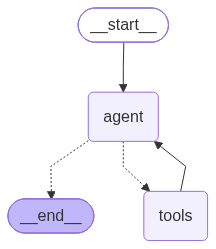

In [17]:
text2sql_agent = create_react_agent(model=llm,
                                    tools=sql_tools,
                                    prompt=SYS_PROMPT)
text2sql_agent

Run and Test Text2SQL Agent

In [19]:
from IPython.display import display, Markdown

In [20]:
for event in text2sql_agent.stream(
    {"messages": [HumanMessage(content="What are the Top 10 most popular comics?")]},
    stream_mode='values' #returns full agent state with all messages including updates
):
    event["messages"][-1].pretty_print()

print('\n\nFinal Response:\n')
display(Markdown(event["messages"][-1].content))

================================ Human Message =================================

What are the Top 10 most popular comics?
================================== Ai Message ==================================
Tool Calls:
  sql_db_list_tables (call_ng3E5emTX8Kmxr1PDs3CqRho)
 Call ID: call_ng3E5emTX8Kmxr1PDs3CqRho
  Args:
================================= Tool Message =================================
Name: sql_db_list_tables

Branch, Comic, Customer, Employee, Inventory, Publisher, Sale, SaleTransactions
================================== Ai Message ==================================
Tool Calls:
  sql_db_schema (call_BECymrKYJ0dCRpY0CMD2j5hB)
 Call ID: call_BECymrKYJ0dCRpY0CMD2j5hB
  Args:
    table_names: Comic, Sale
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE "Comic" (
	"ComicId" INTEGER NOT NULL, 
	"Title" NVARCHAR(100) NOT NULL, 
	"PublisherId" INTEGER NOT NULL, 
	"Genre" NVARCHAR(50), 
	"Price" NUMERIC(10, 2) NOT NU

Here are the Top 10 most popular comics based on sales:

1. Wolverine: Old Man Logan - 3 copies sold
2. V for Vendetta - 2 copies sold
3. Usagi Yojimbo Volume 1 - 2 copies sold
4. Transformers: All Hail Megatron - 2 copies sold
5. The Killing Joke - 2 copies sold
6. The Boys Volume 1 - 2 copies sold
7. Superman: Red Son - 2 copies sold
8. Punisher: Welcome Back, Frank - 2 copies sold
9. Preacher Volume 1 - 2 copies sold
10. Ms. Marvel Volume 1 - 2 copies sold

In [21]:
def call_text2sql_agent(query, verbose=False):
    
    for event in text2sql_agent.stream(
        {"messages": [HumanMessage(content=query)]},
        stream_mode='values' #returns full agent state with all messages including updates
    ):
        if verbose:
            event["messages"][-1].pretty_print()

    print('\n\nFinal Response:\n')
    display(Markdown(event["messages"][-1].content))

In [22]:
call_text2sql_agent(query="What are the Top 10 most popular comics?",
                    verbose=True)

================================ Human Message =================================

What are the Top 10 most popular comics?
================================== Ai Message ==================================
Tool Calls:
  sql_db_list_tables (call_qXcAUUXuWQT0I4u9y5ZKZGGN)
 Call ID: call_qXcAUUXuWQT0I4u9y5ZKZGGN
  Args:
================================= Tool Message =================================
Name: sql_db_list_tables

Branch, Comic, Customer, Employee, Inventory, Publisher, Sale, SaleTransactions
================================== Ai Message ==================================
Tool Calls:
  sql_db_schema (call_OeTCKKTfv6apuw3K2mUVUuqb)
 Call ID: call_OeTCKKTfv6apuw3K2mUVUuqb
  Args:
    table_names: Comic, Sale
================================= Tool Message =================================
Name: sql_db_schema


CREATE TABLE "Comic" (
	"ComicId" INTEGER NOT NULL, 
	"Title" NVARCHAR(100) NOT NULL, 
	"PublisherId" INTEGER NOT NULL, 
	"Genre" NVARCHAR(50), 
	"Price" NUMERIC(10, 2) NOT NU

Here are the Top 10 most popular comics based on sales:

1. Wolverine: Old Man Logan - 3 copies sold
2. Superman: Red Son - 2 copies sold
3. Ms. Marvel Volume 1 - 2 copies sold
4. Iron Man: Extremis - 2 copies sold
5. Locke & Key Volume 1 - 2 copies sold
6. V for Vendetta - 2 copies sold
7. The Boys Volume 1 - 2 copies sold
8. Lumberjanes Volume 1 - 2 copies sold
9. Punisher: Welcome Back, Frank - 2 copies sold
10. Invincible Volume 1 - 2 copies sold

In [23]:
call_text2sql_agent(query="What are the top 5 customers with most comics purchased?",
                    verbose=False)



Final Response:



The top 5 customers with the most comics purchased are:

1. Tony Stark - 8 comics
2. Sarah Connor - 7 comics
3. Natasha Romanoff - 6 comics
4. Clark Kent - 6 comics
5. Diana Prince - 6 comics